## Short-Term Indoor CO2 Prediction for Ventilation Monitoring

In [22]:
"""Import analysis dependencies and select an optional PyTorch device.

The pandas/NumPy workflow runs on CPU; device selection is retained for
possible later PyTorch experiments and does not accelerate pandas."""

from pathlib import Path
import json
import pandas as pd
try:
    import torch
except ImportError:
    torch = None

if torch is not None and torch.cuda.is_available():
    device = torch.device("cuda")
elif torch is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu") if torch is not None else "cpu"

print("Using device:", device)

Using device: cuda


In [23]:
"""Locate the raw dataset folder and load environmental records.

Inputs are the named CSV files and optional location workbook. Sensor IDs
remain strings; database timestamps are UTC. Occupancy is deferred by default.
NROWS=None loads all environmental records. Raises FileNotFoundError if the
folder is absent; a missing Excel reader skips only location metadata."""

DATA_FOLDER = "MMA3001 Dataset - MSI Occupancy and Environmental"
search_locations = [Path.cwd(), *Path.cwd().parents]
data_dir = next((p / DATA_FOLDER for p in search_locations if (p / DATA_FOLDER).is_dir()), None)
if data_dir is None:
    raise FileNotFoundError(f"Could not find {DATA_FOLDER!r} from {Path.cwd()}")

occupancy_path = data_dir / "5occupancySensor_MayToDec2024_9MRows.csv"
environment_path = data_dir / "5EnvSensor_MayToDec2024_180kRows.csv"
locations_path = data_dir / "Sensor ID and Locations.xlsx"

# Set to a row count (e.g. 10_000) for a quick preview; None loads all rows.
NROWS = None
LOAD_OCCUPANCY = False  # Deferred until room mapping is resolved.
occupancy = pd.read_csv(
    occupancy_path, nrows=NROWS,
    dtype={"deviceid": "string", "floorspaceid": "string"},
) if LOAD_OCCUPANCY else None
environment = pd.read_csv(
    environment_path, nrows=NROWS, dtype={"sensorid": "string"},
)
# UTC keeps timestamps comparable across daylight-saving offsets.
for column in ["collecteddate", "occupancystatuschangedate"]:
    if occupancy is not None:
        occupancy[column] = pd.to_datetime(occupancy[column], format="mixed", utc=True)
for column in ["createdate", "processdate"]:
    environment[column] = pd.to_datetime(environment[column], format="mixed", utc=True)

# Keep both workbook sheets, including the occupancy sheet's original warning.
try:
    location_sheets = pd.read_excel(locations_path, sheet_name=None, dtype="string")
except ImportError:
    location_sheets = {}
    print("Location workbook skipped. To enable it, run %pip install openpyxl in this kernel.")
locations = location_sheets.get("ENV", pd.DataFrame())
occupancy_locations = location_sheets.get("OCC (Incorrect Data - SpaceFloo", pd.DataFrame())

print(f"Data folder: {data_dir}")
print(f"Occupancy: {occupancy.shape if occupancy is not None else 'deferred'}")
print(f"Environment: {environment.shape}")
for sheet_name, sheet in location_sheets.items():
    print(f"Locations [{sheet_name}]: {sheet.shape}")
display(environment.head(), locations.head())

Data folder: c:\Users\ezhu2\Documents\MMA3001\MMA3001-Eric-Zhu\MMA3001 Dataset - MSI Occupancy and Environmental
Occupancy: deferred
Environment: (179447, 8)
Locations [ENV]: (78, 6)
Locations [OCC (Incorrect Data - SpaceFloo]: (89, 7)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-28 16:11:58.210358+00:00,2024-02-28 16:11:58.210358+00:00
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 06:09:08.833822+00:00,2024-02-29 06:09:08.833822+00:00
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 06:09:12.444245+00:00,2024-02-29 06:09:12.444245+00:00
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 06:10:24.443407+00:00,2024-02-29 06:10:24.443407+00:00
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 06:11:11.348578+00:00,2024-02-29 06:11:11.348578+00:00


,Building,Floor/Room,Area,Physical Label,Sensor,ID
0,60,1-PS01,Corridor,ES1104,Env,6012003000486
1,69,1-PS02,Breakout,ES2113,Env,6012003000882
2,60,1.40,Board Room,ES1102,Env,6012003000462
3,60,1.41,Open Office,ES1110,Env,6012003000424
4,60,1.41A,Focus Room 1,ES1101,Env,6012003000448


## Audit environmental measurements
Use the measurement times inside JSON, rather than database creation times. Remove exact repeated measurements; exclude conflicting values at the same sensor/time/variable instead of choosing one arbitrarily. No interpolation or target filling is used. Nonpositive CO2 is excluded; other unusual values remain for inspection.

In [24]:
"""Extract measured CO2, temperature and humidity from environmental JSON.

Produces co2 with UTC measurement timestamps, ppm, degrees Celsius and the
source humidity units. Invalid rows, exact duplicates, conflicting keys and
nonpositive CO2 are audited and excluded. No values are interpolated."""

from time import perf_counter
import numpy as np
started = perf_counter()
records, parse_errors = [], []
for row in environment.itertuples(index=False):
    try:
        payload = json.loads(row.jsondata)
        for item in payload:
            name = item.get("variable", {}).get("name")
            if name not in ["Carbon dioxide", "Temperature", "Humidity"]:
                continue
            for reading in item.get("values", []):
                records.append((row.sensorid, reading.get("time"), name, reading.get("value")))
    except (ValueError, TypeError, AttributeError) as exc:
        parse_errors.append((row.id, str(exc)))
readings = pd.DataFrame(records, columns=["sensorid", "timestamp", "variable", "value"])
readings["timestamp"] = pd.to_datetime(pd.to_numeric(readings["timestamp"], errors="coerce"), unit="s", utc=True, errors="coerce")
readings["value"] = pd.to_numeric(readings["value"], errors="coerce")
invalid = readings[["sensorid", "timestamp", "variable", "value"]].isna().any(axis=1) | ~np.isfinite(readings["value"])
invalid_count = int(invalid.sum())
readings = readings.loc[~invalid].copy()
exact_duplicates = int(readings.duplicated().sum())
readings = readings.drop_duplicates()
keys = ["sensorid", "timestamp", "variable"]
conflicts = readings.duplicated(keys, keep=False)
conflicting_readings = readings.loc[conflicts].copy()
readings = readings.loc[~conflicts]
environment_wide = readings.pivot(index=["sensorid", "timestamp"], columns="variable", values="value").reset_index()
co2 = environment_wide.rename(columns={"Carbon dioxide": "co2_ppm"}).sort_values(["sensorid", "timestamp"])
nonpositive_co2 = int(co2["co2_ppm"].le(0).sum())
co2 = co2.loc[co2["co2_ppm"].gt(0)].copy()
print({"JSON errors": len(parse_errors), "invalid readings": invalid_count,
       "exact duplicates removed": exact_duplicates, "conflicting readings excluded": len(conflicting_readings),
       "nonpositive CO2 excluded": nonpositive_co2})
print(f"Parsing and cleaning: {perf_counter() - started:.2f} seconds")
display(co2.head(), co2[["co2_ppm", "Temperature", "Humidity"]].describe())

{'JSON errors': 0, 'invalid readings': 0, 'exact duplicates removed': 409812, 'conflicting readings excluded': 0, 'nonpositive CO2 excluded': 0}
Parsing and cleaning: 8.23 seconds


variable,sensorid,timestamp,co2_ppm,Humidity,Temperature
0,6012002000227,2023-12-11 05:07:53+00:00,666.0,69.0,24.0
1,6012002000241,2023-12-11 05:52:45+00:00,603.0,66.0,23.8
2,6012002000241,2025-05-19 13:08:04+00:00,447.0,45.0,15.5
3,6012002000326,2023-12-11 05:00:57+00:00,525.0,68.0,23.8
4,6012002000326,2025-09-07 10:09:30+00:00,410.0,60.0,19.0


variable,co2_ppm,Temperature,Humidity
count,42843.000000,42843.000000,42843.000000
mean,451.695750,21.553906,50.958663
std,34.378194,3.459916,10.148825
min,400.000000,11.800000,17.000000
25%,431.000000,19.000000,44.000000
50%,443.000000,22.000000,50.000000
75%,461.000000,23.500000,58.000000
max,1387.000000,37.500000,84.000000


In [25]:
"""Audit sensor sampling intervals and select the longest contiguous period.

Inputs are cleaned measurements. Outputs include sensor_audit, period_audit
and sensor_series. A gap over 30 minutes starts a new period. Selection uses
time coverage only. Requires at least one valid sensor observation."""

coverage_rows = []
for sensor, frame in co2.groupby("sensorid"):
    times = frame["timestamp"].sort_values()
    intervals = times.diff().dt.total_seconds().dropna()
    typical = intervals.median()
    coverage_rows.append({"sensorid": sensor, "observations": len(times),
        "start": times.min(), "end": times.max(), "median_interval_seconds": typical,
        "p95_interval_seconds": intervals.quantile(.95),
        "gaps_over_30min": int((intervals > 1800).sum()),
        "largest_gap_hours": intervals.max() / 3600})
sensor_audit = pd.DataFrame(coverage_rows).sort_values("observations", ascending=False)
display(sensor_audit)
# Identify contiguous periods using an explicit 30-minute outage threshold.
MAX_GAP = pd.Timedelta("30min")
co2["segment"] = co2.groupby("sensorid")["timestamp"].diff().gt(MAX_GAP).groupby(co2["sensorid"]).cumsum()
period_audit = co2.groupby(["sensorid", "segment"]).agg(
    observations=("timestamp", "size"), start=("timestamp", "min"), end=("timestamp", "max"))
period_audit["duration_days"] = (period_audit["end"] - period_audit["start"]).dt.total_seconds() / 86400
period_audit = period_audit.sort_values(["duration_days", "observations"], ascending=False)
display(period_audit.head(10))
# Selection uses timestamp coverage only, never forecasting error or test values.
selected_sensor, selected_segment = period_audit.index[0]
sensor_series = co2.loc[(co2["sensorid"] == selected_sensor) & (co2["segment"] == selected_segment)].set_index("timestamp").sort_index()
print("Selected sensor:", selected_sensor, "period:", sensor_series.index.min(), "to", sensor_series.index.max())
display(sensor_series[["co2_ppm", "Temperature", "Humidity"]].describe())

,sensorid,observations,start,end,median_interval_seconds,p95_interval_seconds,gaps_over_30min,largest_gap_hours
2,6012002000326,29039,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,600.0,1200.0,62,15269.142500
4,6012002000869,13800,2024-02-29 06:04:56+00:00,2024-06-13 17:45:44+00:00,600.0,1200.0,0,0.499722
1,6012002000241,2,2023-12-11 05:52:45+00:00,2025-05-19 13:08:04+00:00,45386119.0,45386119.0,1,12607.255278
0,6012002000227,1,2023-12-11 05:07:53+00:00,2023-12-11 05:07:53+00:00,NaN,NaN,0,NaN
3,6012002000777,1,2023-05-05 22:42:45+00:00,2023-05-05 22:42:45+00:00,NaN,NaN,0,NaN


observations                     start  \
sensorid      segment                                           
6012002000869 0               13800 2024-02-29 06:04:56+00:00   
6012002000326 2                9012 2025-09-11 12:39:34+00:00   
              62               5909 2026-03-09 21:02:04+00:00   
              60               5590 2026-01-12 06:21:21+00:00   
              36               5391 2025-11-30 06:50:43+00:00   
              61               1428 2026-02-27 07:31:56+00:00   
              3                1068 2025-11-17 19:40:35+00:00   
              56                 99 2026-01-11 05:31:19+00:00   
              9                  78 2025-11-26 06:00:42+00:00   
              51                 79 2026-01-10 09:31:19+00:00   

                                            end  duration_days  
sensorid      segment                                           
6012002000869 0       2024-06-13 17:45:44+00:00     105.486667  
6012002000326 2       2025-11-17 18:20:35+00:00      67.236817  
              62      2026-04-22 13:12:41+00:00      43.674039  
              60      2026-02-22 19:41:53+00:00      41.555926  
              36      2026-01-09 03:31:17+00:00      39.861505  
              61      2026-03-09 20:22:04+00:00      10.534815  
              3       2025-11-25 23:20:42+00:00       8.152859  
              56      2026-01-12 01:11:20+00:00       0.819456  
              9       2025-11-26 21:20:42+00:00       0.638889  
              51      2026-01-11 00:21:19+00:00       0.618056

Selected sensor: 6012002000869 period: 2024-02-29 06:04:56+00:00 to 2024-06-13 17:45:44+00:00


variable,co2_ppm,Temperature,Humidity
count,13800.000000,13800.000000,13800.000000
mean,473.985217,23.089514,45.033841
std,39.403080,1.163156,7.394367
min,403.000000,19.000000,26.000000
25%,444.000000,22.500000,40.000000
50%,463.000000,23.300000,45.000000
75%,494.000000,23.800000,49.000000
max,646.000000,28.500000,75.000000


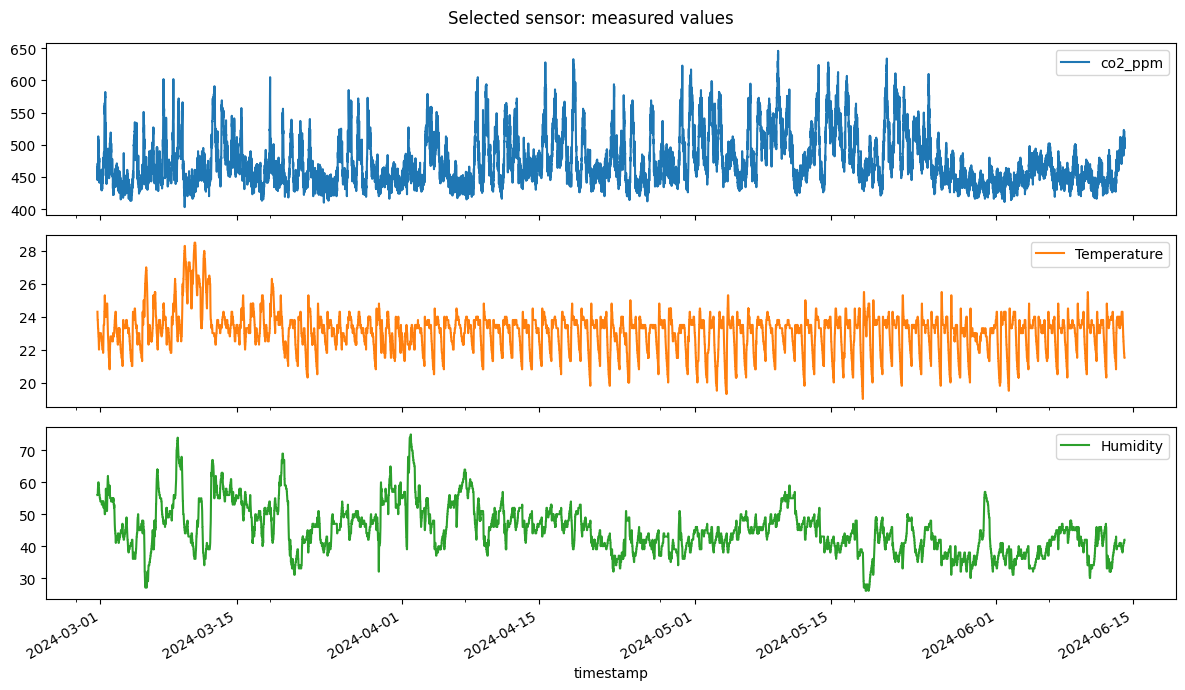

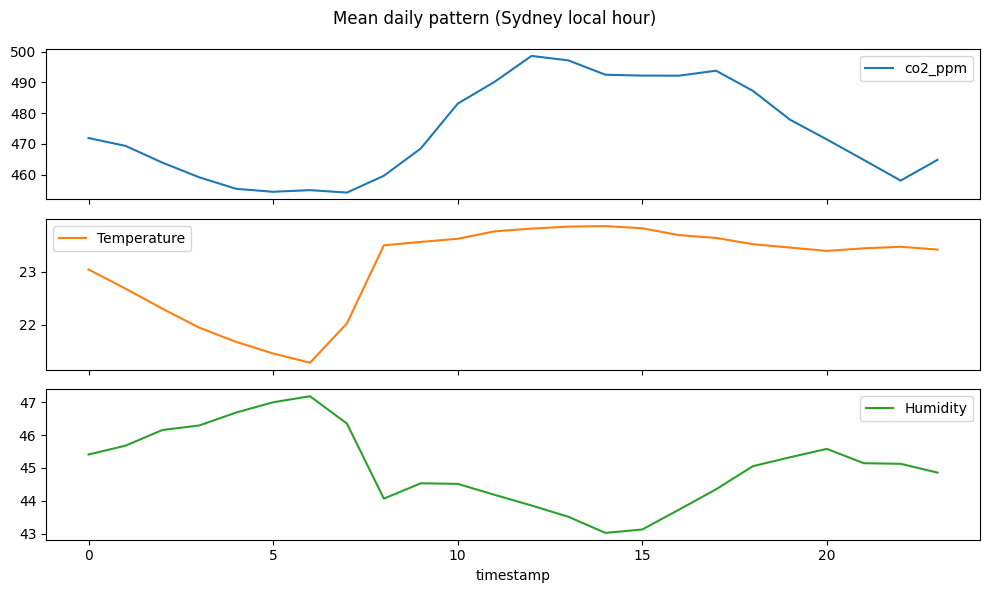

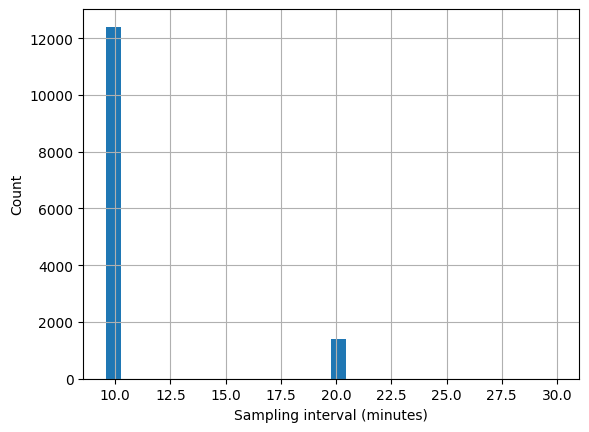

In [26]:
"""Plot observed histories, local-hour averages and sampling intervals.

Uses sensor_series and Sydney local time for descriptive plots. If matplotlib
is unavailable, prints setup guidance and leaves the analytical workflow usable."""

# Optional visual checks; tables and splits do not require matplotlib.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("For time-series and daily-pattern plots, run %pip install matplotlib, then rerun this cell.")
else:
    local_series = sensor_series.copy()
    local_series.index = local_series.index.tz_convert("Australia/Sydney")
    local_series[["co2_ppm", "Temperature", "Humidity"]].plot(subplots=True, figsize=(12, 7), title="Selected sensor: measured values")
    plt.tight_layout()
    plt.show()
    local_series.groupby(local_series.index.hour)[["co2_ppm", "Temperature", "Humidity"]].mean().plot(subplots=True, figsize=(10, 6), title="Mean daily pattern (Sydney local hour)")
    plt.tight_layout()
    plt.show()
    local_series.index.to_series().diff().dt.total_seconds().div(60).hist(bins=30)
    plt.xlabel("Sampling interval (minutes)")
    plt.ylabel("Count")
    plt.show()


## Build forecasts and split chronologically
The selected sensor samples about every 10 minutes. An exact 15-minute measured target is therefore unsupported. Use a **20-minute horizon** with a 2-minute target tolerance, without interpolating targets. Historical CO2 at 10 and 20 minutes ago is matched backward only, allowing 2 minutes of staleness. Compute the rate using actual elapsed time. Review the actual horizon summary below.

Split forecast issue times into approximately 60% training, 20% validation and 20% final test. Purge earlier examples whose target reaches the next period. Historical inputs from a preceding period are available at forecast time and may be used. Tune models on validation only and reserve the final test for the selected configuration. Fit any learned scaling or imputation on training only. Revisit the original 15-minute objective if higher-frequency data becomes available.


In [ ]:
"""Build observed future targets, historical features and chronological splits.

Inputs are a single sensor_series. Outputs are forecast_data, train, validation,
test, X_train/X_val/X_test and y_train/y_val/y_test. CO2 is in ppm and its
backward rate is ppm/minute. The 20-minute horizon reflects 10-minute sampling;
2-minute matching tolerance never fills targets. Boundary targets are purged.
Raises ValueError below 100 usable forecasts; asserts nonempty ordered splits."""

HORIZON = pd.Timedelta("20min")
TOLERANCE = pd.Timedelta("2min")

base = sensor_series[["co2_ppm", "Temperature", "Humidity"]].reset_index()
features = base.rename(columns={"timestamp": "issue_time"}).copy()

# Backward matching prevents future measurements from entering lag inputs.
for minutes in [10, 20]:
    lookup = base[["timestamp", "co2_ppm"]].rename(columns={"timestamp": f"lag_time_{minutes}", "co2_ppm": f"co2_lag_{minutes}min"})
    features["lookup_time"] = features["issue_time"] - pd.Timedelta(minutes=minutes)
    features = pd.merge_asof(features.sort_values("lookup_time"), lookup,
        left_on="lookup_time", right_on=f"lag_time_{minutes}", direction="backward", tolerance=TOLERANCE)
    
features = features.drop(columns="lookup_time").sort_values("issue_time")
elapsed_minutes = (features["issue_time"] - features["lag_time_10"]).dt.total_seconds() / 60
features["co2_rate_ppm_per_min"] = (features["co2_ppm"] - features["co2_lag_10min"]) / elapsed_minutes
features["desired_target_time"] = features["issue_time"] + HORIZON

# Targets are measured observations matched separately from historical inputs.
targets = base[["timestamp", "co2_ppm"]].rename(columns={"timestamp": "target_time", "co2_ppm": "target_co2_ppm"})
forecast_data = pd.merge_asof(features.sort_values("desired_target_time"), targets,
    left_on="desired_target_time", right_on="target_time", direction="nearest", tolerance=TOLERANCE)
feature_columns = ["co2_ppm", "co2_lag_10min", "co2_lag_20min", "Temperature", "Humidity", "co2_rate_ppm_per_min"]
rows_before = len(forecast_data)
forecast_data = forecast_data.dropna(subset=feature_columns + ["target_time", "target_co2_ppm"]).reset_index(drop=True)
forecast_data["actual_horizon_minutes"] = (forecast_data["target_time"] - forecast_data["issue_time"]).dt.total_seconds() / 60
print(f"Usable forecasts: {len(forecast_data):,}; excluded for missing inputs/targets: {rows_before - len(forecast_data):,}")
display(forecast_data["actual_horizon_minutes"].describe())
if len(forecast_data) < 100:
    raise ValueError("Too few forecasts. Review sensor coverage, lag intervals and target tolerance.")
validation_start = forecast_data["issue_time"].iloc[int(.6 * len(forecast_data))]
test_start = forecast_data["issue_time"].iloc[int(.8 * len(forecast_data))]

# Remove earlier forecasts whose outcomes reach the following split.
train = forecast_data.loc[(forecast_data.issue_time < validation_start) & (forecast_data.target_time < validation_start)].copy()
validation = forecast_data.loc[(forecast_data.issue_time >= validation_start) & (forecast_data.issue_time < test_start) & (forecast_data.target_time < test_start)].copy()
test = forecast_data.loc[forecast_data.issue_time >= test_start].copy()
assert all(len(part) > 0 for part in [train, validation, test])
assert train.target_time.max() < validation.issue_time.min()
assert validation.target_time.max() < test.issue_time.min()
X_train, y_train = train[feature_columns].copy(), train["target_co2_ppm"].copy()
X_val, y_val = validation[feature_columns].copy(), validation["target_co2_ppm"].copy()
X_test, y_test = test[feature_columns].copy(), test["target_co2_ppm"].copy()
split_summary = pd.DataFrame([{"split": name, "rows": len(part), "start": part.issue_time.min(), "last_issue": part.issue_time.max(), "last_target": part.target_time.max()} for name, part in [("train", train), ("validation", validation), ("test", test)]])

display(split_summary)
print("Purged boundary forecasts:", len(forecast_data) - len(train) - len(validation) - len(test))

Usable forecasts: 7,855; excluded for missing inputs/targets: 5,945


count    7855.000000
mean       19.998994
std         0.015381
min        19.566667
25%        20.000000
50%        20.000000
75%        20.000000
max        20.350000
Name: actual_horizon_minutes, dtype: float64

,split,rows,start,last_issue,last_target
0,train,4712,2024-02-29 06:54:57+00:00,2024-05-08 15:55:29+00:00,2024-05-08 16:15:29+00:00
1,validation,1569,2024-05-08 16:25:29+00:00,2024-05-27 12:35:35+00:00,2024-05-27 12:55:35+00:00
2,test,1571,2024-05-27 13:05:35+00:00,2024-06-13 17:25:44+00:00,2024-06-13 17:45:44+00:00


Purged boundary forecasts: 3


In [ ]:
"""Evaluate persistence on training and validation and export reproducible data.

Inputs are the prepared splits and audit tables. Outputs are baseline_results
and CSV files under prepared_data. The test split is exported without scoring.
Exports replace files of the same name and require write access."""

# Establish baseline on training/validation; final test remains reserved.
def persistence_metrics(part):
    """Score the forecast that future CO2 equals current measured CO2.

    Args:
        part (pandas.DataFrame): Nonempty prepared split with numeric
            co2_ppm and target_co2_ppm columns, both in ppm. Call with
            training or validation data during model development.

    Returns:
        dict: MAE_ppm, RMSE_ppm, mean_signed_error_ppm and prediction_seconds.
            Signed error is prediction minus observation; positive means
            overprediction. Timing covers array extraction only, excluding
            error calculations, and is a rough single-call measurement.
            Missing values propagate to metrics; empty inputs yield NaN.

    Raises:
        KeyError: If a required CO2 column is missing.
        TypeError: If column values cannot support numeric arithmetic.

    Examples:
        sample = pd.DataFrame({"co2_ppm": [400., 420.],
        ...                        "target_co2_ppm": [410., 410.]})
        persistence_metrics(sample)["MAE_ppm"]
        10.0
    """
    before = perf_counter()
    prediction = part["co2_ppm"].to_numpy()
    prediction_seconds = perf_counter() - before
    # Positive residuals mean that persistence overpredicts measured CO2.
    error = prediction - part["target_co2_ppm"].to_numpy()
    return {"MAE_ppm": np.abs(error).mean(), "RMSE_ppm": np.sqrt(np.mean(error**2)),
            "mean_signed_error_ppm": error.mean(), "prediction_seconds": prediction_seconds}
baseline_results = pd.DataFrame({"train": persistence_metrics(train), "validation": persistence_metrics(validation)}).T
display(baseline_results)
# Export reproducible datasets and audits next to the notebook; raw files stay in place.
output_dir = data_dir.parent / "prepared_data"
output_dir.mkdir(exist_ok=True)
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    part.to_csv(output_dir / f"{name}.csv", index=False)
sensor_audit.to_csv(output_dir / "sensor_audit.csv", index=False)
period_audit.to_csv(output_dir / "period_audit.csv")
split_summary.to_csv(output_dir / "split_summary.csv", index=False)
print("Saved datasets and audit tables to", output_dir)

,MAE_ppm,RMSE_ppm,mean_signed_error_ppm,prediction_seconds
train,10.679754,13.900042,0.03629,0.000149
validation,10.643722,13.830348,-0.06501,0.000060


Saved datasets and audit tables to c:\Users\ezhu2\Documents\MMA3001\MMA3001-Eric-Zhu\prepared_data
